In [1]:
# 2 state demo

# from qae import *
# np.random.seed(40552026)

# A = build_A_markov_loss()
# res_loss = run_experiment(A, grover_op(A, 3), p_true=0.034819255, flag_qubit=3, K_max=5)
# summarise(res_loss, "loss")
# plot_results(res_loss, "Estimation error vs query count\n(Markov model, 3-day loss ≤ −5%)", "rmse_vs_N_loss.png")


In [2]:
from qae import *
np.random.seed(40552026)
LABELS = ["00", "01", "02", "10", "11", "12", "20", "21", "22"]

for i, lab in enumerate(LABELS):
    a, b = int(lab[0]), int(lab[1])
    p = Statevector(build_A_v3(a, b)).probabilities([15])[1]
    print(lab, f"{p:.8f}", f"{REF_V3[i]:.8f}", "OK" if abs(p - REF_V3[i]) < 1e-8 else "MISMATCH")
    
A = build_A_v3(2, 2)
Q = grover_op(A, 15)
theta = np.arcsin(np.sqrt(REF_V3[8]))
sv = Statevector(A)
for m in range(5):
    if m > 0:
        sv = sv.evolve(Q)
    print(m, round(sv.probabilities([15])[1], 4), round(np.sin((2*m + 1) * theta) ** 2, 4))
    
print("A':", resources(A))     # ~ (16, 2507, 4483)
print("Q :", resources(Q))     # ~ (16, 5878, ...)


00 0.00202700 0.00202700 OK
01 0.04185743 0.04185743 OK
02 0.29556214 0.29556214 OK
10 0.00959952 0.00959952 OK
11 0.07148326 0.07148326 OK
12 0.63992941 0.63992941 OK
20 0.11950470 0.11950470 OK
21 0.18732675 0.18732675 OK
22 0.78237398 0.78237398 OK
0 0.7824 0.7824
1 0.0131 0.0131
2 0.5702 0.5702
3 0.936 0.936
4 0.114 0.114
A': (16, 2507, 4483)
Q : (16, 5878, 9388)



=== v3_00 ===
method  Classical       EIS       LIS
N                                    
400      0.002183  0.001397  0.001434
900      0.001522  0.000771  0.000783
1600          NaN       NaN  0.000472
1800     0.001030  0.000428       NaN
2500          NaN       NaN  0.000352
3500     0.000712  0.000217       NaN
LIS: slope -0.78 (from 2nd point: -0.79)
EIS: slope -0.86 (from 2nd point: -0.93)
Classical: slope -0.52 (from 2nd point: -0.56)
At N = 3500: EIS 0.00022 vs classical 0.00071 -> 3.3x lower


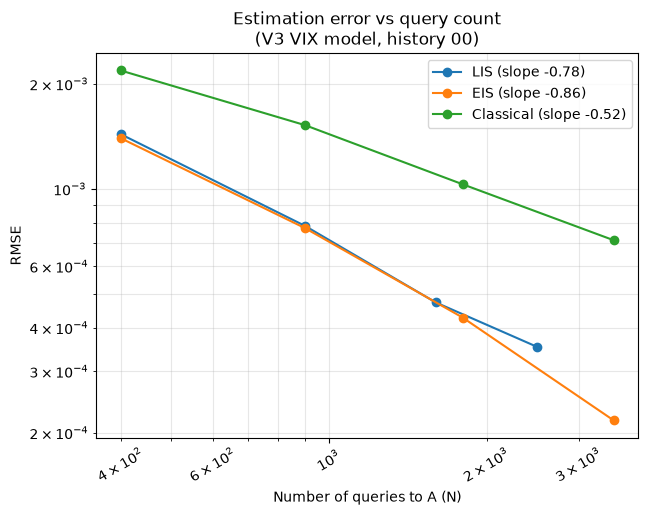


=== v3_01 ===
method  Classical       EIS       LIS
N                                    
400      0.010471  0.006013  0.006287
900      0.006966  0.003288  0.003564
1600          NaN       NaN  0.003190
1800     0.004818  0.001786       NaN
2500          NaN       NaN  0.001575
3500     0.003410  0.001011       NaN
LIS: slope -0.69 (from 2nd point: -0.77)
EIS: slope -0.83 (from 2nd point: -0.87)
Classical: slope -0.52 (from 2nd point: -0.53)
At N = 3500: EIS 0.00101 vs classical 0.00341 -> 3.4x lower


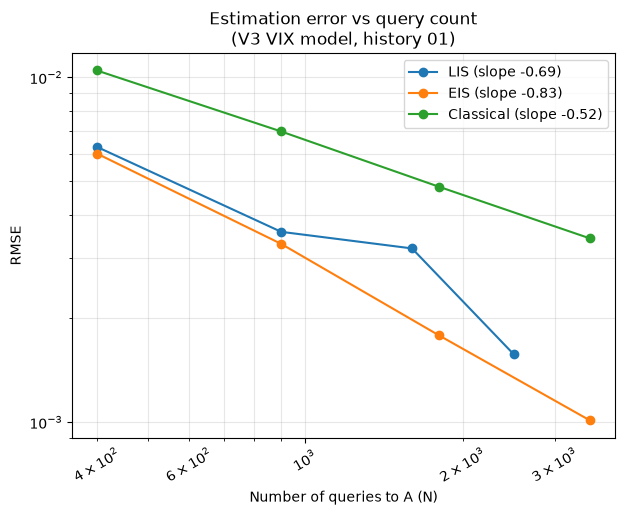


=== v3_11 ===
method  Classical       EIS       LIS
N                                    
400      0.012957  0.008255  0.008793
900      0.008303  0.006290  0.004464
1600          NaN       NaN  0.003160
1800     0.006022  0.002318       NaN
2500          NaN       NaN  0.002137
3500     0.004167  0.001903       NaN
LIS: slope -0.76 (from 2nd point: -0.72)
EIS: slope -0.75 (from 2nd point: -0.88)
Classical: slope -0.52 (from 2nd point: -0.51)
At N = 3500: EIS 0.00190 vs classical 0.00417 -> 2.2x lower


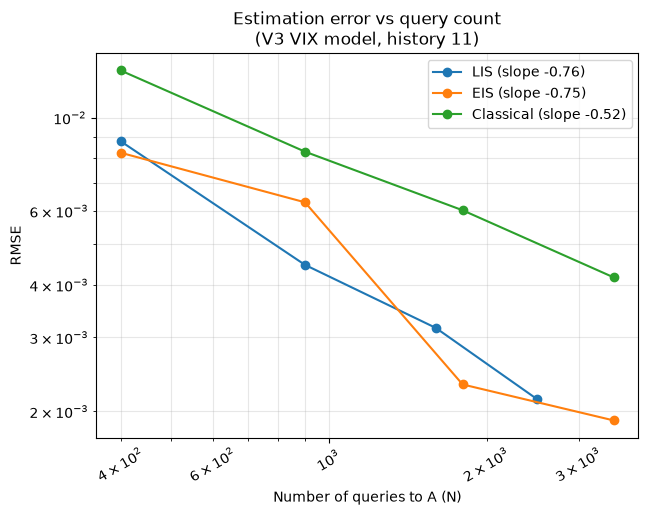


=== v3_12 ===
method  Classical       EIS       LIS
N                                    
400      0.023137  0.022764  0.025144
900      0.015671  0.013135  0.013318
1600          NaN       NaN  0.005412
1800     0.010997  0.004845       NaN
2500          NaN       NaN  0.003680
3500     0.007977  0.003414       NaN
LIS: slope -1.09 (from 2nd point: -1.27)
EIS: slope -0.93 (from 2nd point: -1.00)
Classical: slope -0.49 (from 2nd point: -0.50)
At N = 3500: EIS 0.00341 vs classical 0.00798 -> 2.3x lower


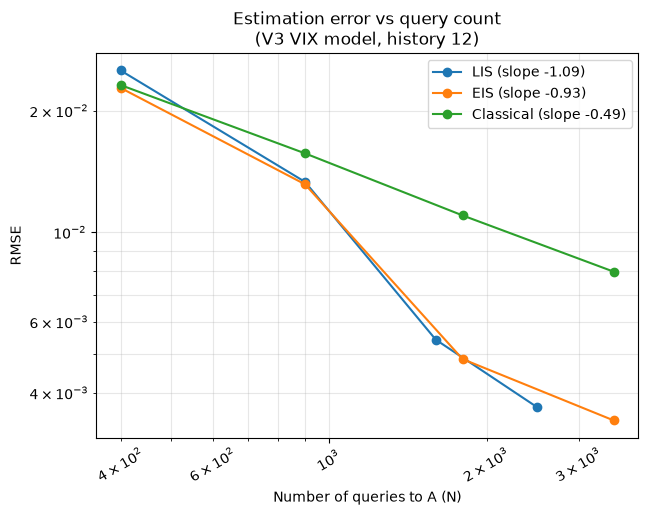


=== v3_22 ===
method  Classical       EIS       LIS
N                                    
400      0.020350  0.033641  0.032032
900      0.014808  0.006645  0.007405
1600          NaN       NaN  0.004682
1800     0.010077  0.004114       NaN
2500          NaN       NaN  0.003222
3500     0.007001  0.002030       NaN
LIS: slope -1.24 (from 2nd point: -0.81)
EIS: slope -1.25 (from 2nd point: -0.87)
Classical: slope -0.50 (from 2nd point: -0.55)
At N = 3500: EIS 0.00203 vs classical 0.00700 -> 3.4x lower


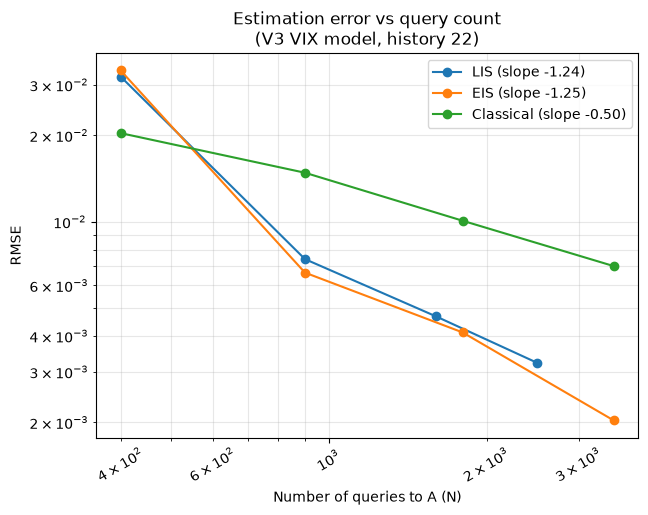

In [3]:
results_v3 = {}
for lab in ["00", "01", "11", "12", "22"]:
    a, b = int(lab[0]), int(lab[1])
    A = build_A_v3(a, b)
    Q = grover_op(A, 15)
    p_true = REF_V3[LABELS.index(lab)]
    res = run_experiment(A, Q, p_true)          # V3 defaults: flag_qubit=15, K_max=4
    summarise(res, f"v3_{lab}")
    plot_results(res, f"Estimation error vs query count\n(V3 VIX model, history {lab})",
                 f"rmse_vs_N_v3_{lab}.png")
    results_v3[lab] = res
